In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} > /dev/null 2>&1
    
    print("必要な依存パッケージをインストール中...")
    %cd /content/{repo_name}
    !pip install -q -r requirements.txt
    !pip install -q -e .
    
    print("作業ディレクトリを該当章へ移動中...")
    %cd /content/{repo_name}/1
    print("✅ 準備完了！このまま下のセルを実行して学習を開始できます。")
else:
    _repo_root = Path.cwd().parent if Path.cwd().name == '1' else Path.cwd()
    if str(_repo_root) not in sys.path:
        sys.path.insert(0, str(_repo_root))
    print("✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。")


✅ ローカル環境で実行中: リポジトリルートを sys.path に設定しました。


# 第1章 PCの仕組みとハローワールド — 1.3 WSLでのやり方 (*Working with WSL*)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/1/1.3_Working_with_WSL.ipynb)

本節では、Windows 環境において 64ビット自作OS **MikanOS** の開発を行うためのデファクトスタンダード基盤である **WSL (*Windows Subsystem for Linux*)**、とりわけ現代の主流である **WSL2** の内部アーキテクチャ、ホスト Windows とのファイルシステム共有機構（**DrvFs** / **9P** / **virtio-fs**）、および実機ブート用 USB メモリへのアクセス手法を、システムプログラミングの視点から徹底的に解明します。

---

### 🎯 本節の学習目標
1. **WSL1 と WSL2 の根本的アーキテクチャ差異の理解**:
   - システムコール変換層（*LXCore.sys*）によるエミュレーション vs 軽量 Hyper-V ユーティリティ VM 上で動く純正 Linux カーネルの違いを把握する。
   - なぜ OS 自作や EDK II ビルドには WSL2 が不可欠なのか、その技術的必然性を学ぶ。
2. **クロスファイルシステム共有機構と DrvFs の数理**:
   - `/mnt/c` や `/mnt/d` といった Windows ドライブのマウント仕様、Plan 9 プロトコル（9P）および virtio-fs の通信オーバーヘッドを理解する。
   - DrvFs のマウントオプション（`metadata`, `case`, `uid`, `gid`, `umask`, `fmask`, `dmask`）による POSIX パーミッション計算式を導出・実証する。
   - 「なぜ `/mnt/c/` 直下でビルドしてはいけないのか？」という最大の性能落とし穴を定量的に把握する。
3. **USB メモリ・外部メディアへのアクセス手法（2大アプローチ）**:
   - **アプローチ A**: DrvFs を用いたドライブレター単位のファイル共有マウント（`sudo mount -t drvfs D: /mnt/d`）。
   - **アプローチ B**: `usbipd-win`（USB over IP）による USB コントローラの直接パススルー（RAW ブロックデバイス `/dev/sdX` としての制御）。
4. **WSL2 から USB メモリへの BOOTX64.EFI 安全配置手順の習得**:
   - ドライブレター同定からマウント、ディレクトリ作成、バイナリ配置、書き込みバッファのフラッシュ（`sync`）までの安全なスクリプトワークフローを実践する。
5. **C++20 による WSL 環境・マウント状態の自動検査**:
   - ホスト環境が WSL1 か WSL2 かネイティブ Linux かを自動判別し、DrvFs マウントオプションとパス変換を検証する C++20 ツールを実装・検証する。


## 1. なぜ Windows 上の OS 自作に WSL2 なのか？ — アーキテクチャの進化

### 1.1 背景と課題：過去の自作OS開発環境の苦難
OS 自作（特に 64ビット UEFI アプリケーションやカーネル開発）では、以下のツール群が標準的に使用されます：
- **Clang / LLVM / LLD**: ELF / PE32+ バイナリをクロスコンパイル可能な現代的コンパイラ基盤
- **EDK II (*EFI Development Kit II*)**: UEFI 公式ファームウェア開発キット（大量の Python/Shell スクリプトと C コードで構成）
- **QEMU (*Quick Emulator*)**: x86-64 仮想マシンエミュレータ
- **GNU Make / CMake**: ビルド自動化ツール

従来、Windows ユーザがこれらのツールを動作させるには以下の選択肢しかありませんでした：
1. **MinGW / Cygwin / MSYS2**: POSIX API を Win32 API にラップしたエミュレーション環境。パス区切り文字（`\` vs `/`）や権限モデル、スクリプト実行速度に多くの不具合や制限を抱えていた。
2. **完全仮想マシン（VMware, VirtualBox）**: 安定性は高いが、メモリ消費が大きく、ホスト Windows とのファイル共有が煩雑で、起動に数十秒〜数分を要した。
3. **デュアルブート（Windows と Linux の共存）**: 最も高速だが、普段の作業環境（ブラウザ、ドキュメント、通信ツール等）との行き来が極めて不便。

これらを一挙に解決したのが **WSL (*Windows Subsystem for Linux*)** です。

---

### 1.2 WSL1 vs WSL2 の内部構造比較

Microsoft は 2 世代の根本的に異なるアーキテクチャで WSL を提供しています：

```text
【WSL1: システムコール変換方式】
+-------------------------------------------------------+
|  Linux ELF64 アプリケーション (bash, gcc, git...)      |
+-------------------------------------------------------+
                           | Linux System Calls (POSIX)
                           v
+-------------------------------------------------------+
|  LXSS / LXCore.sys (Windows NT カーネルドライバ)       |
|  -> Linux システムコールを Windows NT API に動的変換   |
+-------------------------------------------------------+
                           | NT Native API (ZwOpenFile...)
                           v
+-------------------------------------------------------+
|  Windows NT カーネル (ntoskrnl.exe) + NTFS ドライバ    |
+-------------------------------------------------------+
|  物理ハードウェア (CPU, メモリ, ストレージ)            |
+-------------------------------------------------------+

【WSL2: 軽量 Hyper-V ユーティリティ VM + 純正 Linux カーネル】
+-------------------------------------------------------+
|  Linux ELF64 アプリケーション (bash, clang, EDK II)   |
+-------------------------------------------------------+
                           | 100% 純正 Linux システムコール
                           v
+-------------------------------------------------------+
|  純正 Linux カーネル (Microsoft-Standard 5.x/6.x)     |
|  - 独立したページテーブル (CR3), cgroups, ext4 ドライバ|
+-------------------------------------------------------+
        | ext4 ブロック I/O             | 9P/virtio-fs IPC
        v                               v
+------------------------+      +-----------------------+
| 仮想ディスク (VHDX)     |      | DrvFs (/mnt/c, /mnt/d)|
+------------------------+      +-----------------------+
                           |
                           v
+-------------------------------------------------------+
|  Hyper-V ハイパーバイザ (Type-1 Hypervisor / VT-x)     |
+-------------------------------------------------------+
|  Windows 11/10 ホスト OS  |  物理ハードウェア          |
+-------------------------------------------------------+
```

| 比較項目 | **WSL1** | **WSL2 (推奨)** | OS自作における意味 |
|---|---|---|---|
| **カーネルの実体** | なし（NTカーネルによるエミュレーション） | **純正 Linux カーネル** (x86-64) | 100% のシステムコール互換性を保証 |
| **ファイルシステム** | NTFS 直接共有 | **仮想ディスク (VHDX) 上の ext4** | 大量ファイルのビルド速度が 5〜10倍高速 |
| **システムコール互換性** | 一部のみ（ptrace, 特殊ioctl未対応） | **完全 (100%)** | Docker, EDK II, FUSE, eBPF が完全動作 |
| **ハードウェア直接制御** | 不可 | **USB/IP 経由で RAW デバイス制御可能** | `usbipd-win` による実機 USB ドライブ直接操作 |
| **起動時間** | 即座 (< 50ms) | **超高速 (< 1秒)** | 独立 VM でありながら体感ゼロ秒で起動 |
| **GUI アプリケーション** | 別途 X サーバ導入が必要 | **WSLg 標準搭載 (Wayland/X11)** | QEMU のグラフィカル画面がそのまま立ち上がる |


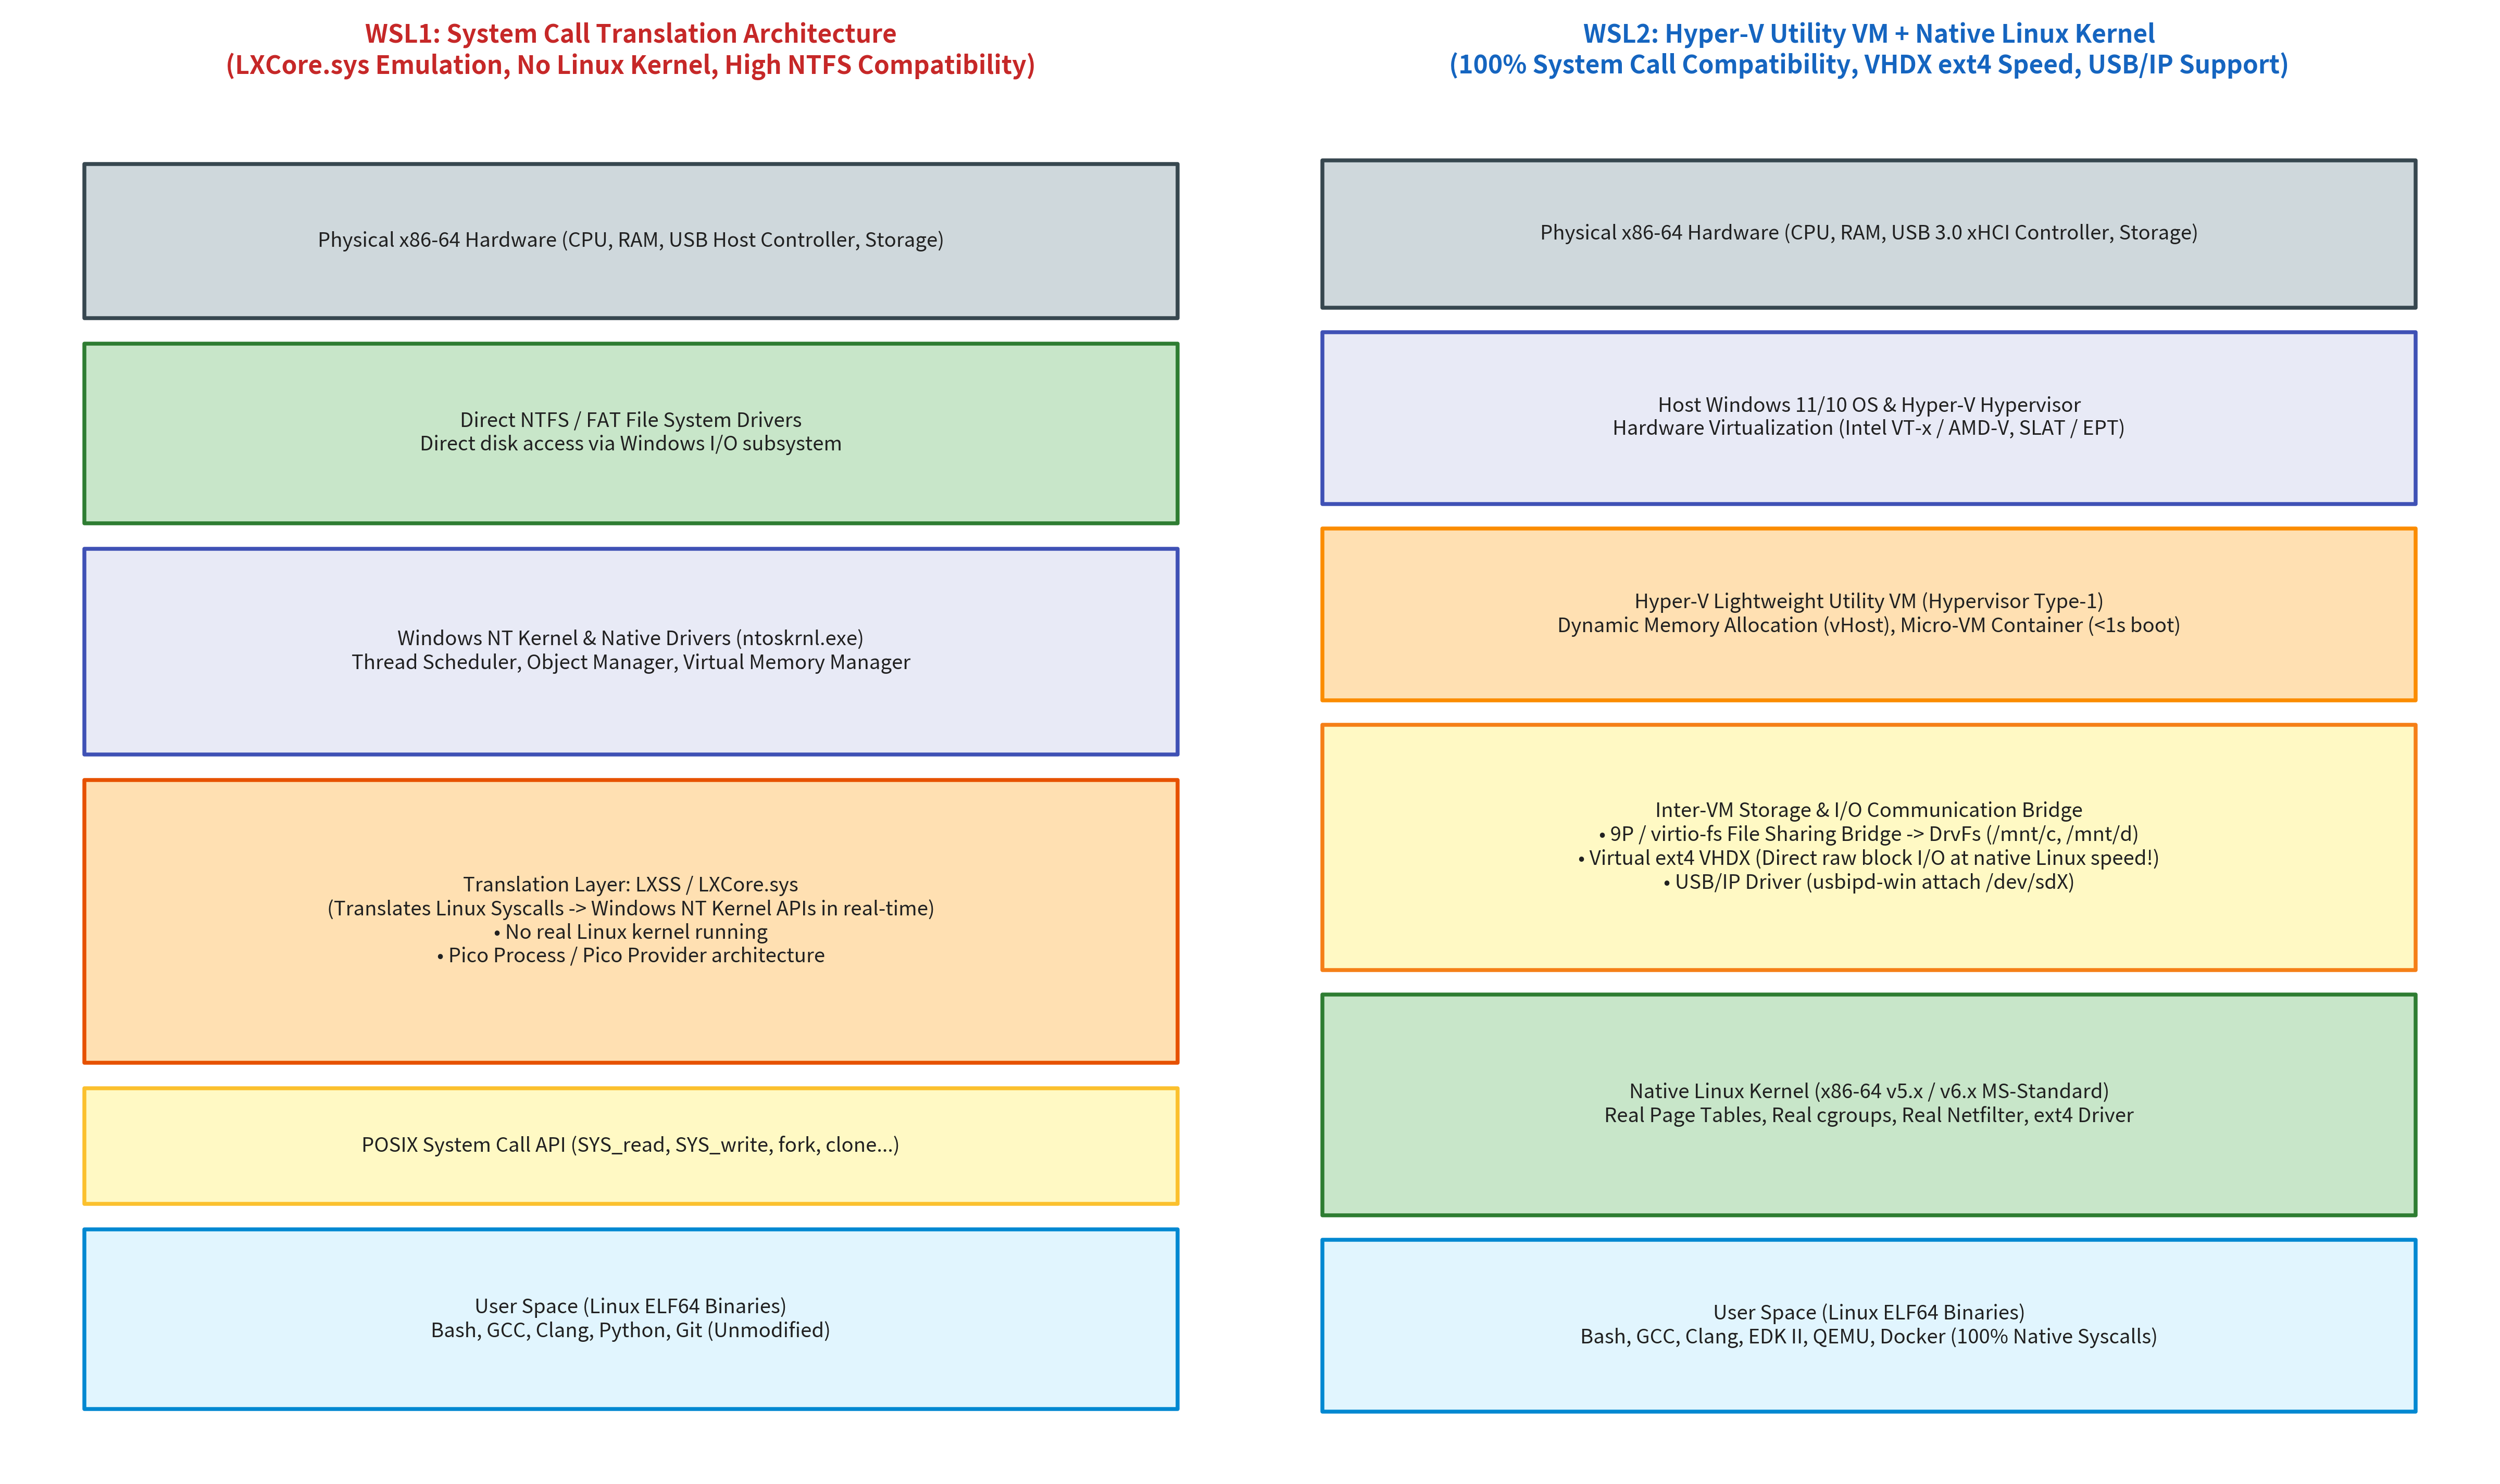

In [2]:
# === WSL1 vs WSL2 アーキテクチャ比較図の生成と表示 ===
import os
from IPython.display import Image, display
from common.os_sim import plot_wsl1_vs_wsl2_architecture

fig_path = "result/fig1_5_wsl1_vs_wsl2_architecture.png"
plot_wsl1_vs_wsl2_architecture(fig_path)
display(Image(filename=fig_path, width=850))


## 2. ホスト Windows ファイルシステムへのアクセス — DrvFs と 9P / virtio-fs

### 2.1 DrvFs マウントの仕組み
WSL2 を起動すると、Windows ホストの各固定ドライブ（`C:`, `D:` など）が、自動的に `/mnt/c`, `/mnt/d` としてマウントされます。
このマウントを支えているのが **DrvFs** (*Drive File System*) プラグインです。

WSL2 は独立した Hyper-V 仮想マシンであるため、ホスト Windows の NTFS / FAT32 パーティションに直接ブロックレベルで触れることはできません。
そこで、ホスト Windows 側で動作するファイルサービスタスクと、WSL2 Linux カーネルの間で、**Plan 9 ネットワークプロトコル (9P)** または最新の **virtio-fs** を介した VM 間通信を行い、ファイル読み書きを実現しています。

---

### 2.2 🚨 最大の落とし穴：ファイルシステム境界の I/O ボトルネック
初学者が最も陥りやすいトラブルが、**「ソースコードを `/mnt/c/Users/...` に置いてビルドしてしまう」** ことです。

```
【危険】 /mnt/c/ 経由でのビルド
Linux (Clang/GCC) <=== 9P/virtio-fs IPC ===> Windows ホスト (NTFS Filter) <===> 物理SSD
  - 1回のファイルオープン・スタット（stat）ごとに VM 間 IPC が発生
  - Windows Defender（アンチウイルス）のリアルタイムスキャンが介入
  - ビルド時間が 5 倍〜10 倍に膨大化する！

【推奨】 WSL2 ネイティブファイルシステム (~/mikanos) でのビルド
Linux (Clang/GCC) <===========================> ext4 (VHDX 仮想ディスク)
  - Linux ネイティブのページキャッシュと ext4 ジャーナリングが直接機能
  - ネイティブ Ubuntu と同等の爆速ビルド速度が発揮される
```

> [!IMPORTANT]
> **黄金律**: **「ソースコードのチェックアウト、EDK II のビルド、カーネルコンパイルは必ず Linux ホームディレクトリ配下（`/home/username/...`）で行うこと」**。  
> `/mnt/c` や `/mnt/d` などの Windows 共有領域は、ビルドが完了した最終成果物（`BOOTX64.EFI` など）を USB メモリやホスト側へコピー・配置する目的でのみ使用するのが鉄則です。

---

### 2.3 DrvFs のマウントオプションとパーミッション数理

NTFS や FAT32 は、Linux の標準的な POSIX パーミッション（`rwxr-xr-x`, `uid`, `gid`, `st_mode`）やシンボリックリンク情報を本来保持していません。
これを解決するため、DrvFs には **`metadata`** オプションが用意されています。

NTFS の拡張属性（*Extended Attributes*, `$EA`）に Linux の `stat` 情報（パーミッション・所有者・デバイス番号）を格納することで、Windows 領域上でも `chmod +x` や `chown` が有効になります。

#### パーミッションの計算式：
`metadata` が有効でない場合、またはメタデータが未記録のファイルに対し、DrvFs は以下のビット演算式で実効パーミッションを決定します：

$$
\text{Mode}_{\text{dir}} = 0777 \ \& \ \sim(\text{dmask} \ | \ \text{umask})
$$
$$
\text{Mode}_{\text{file}} = 0777 \ \& \ \sim(\text{fmask} \ | \ \text{umask})
$$

- `fmask=0111`: 通常ファイルから実行権限ビット（`--x--x--x`）をマスク（除外）する。
- `dmask=0000`: ディレクトリの走査・侵入権限（`rwxr-xr-x`）を維持する。
- `case=dir`: 各ディレクトリ単位で大文字小文字の区別（Case Sensitivity）フラグを尊重する。


In [3]:
# === Python による DrvFs マウントオプション解析とパーミッション計算 ===
from common.os_sim import DrvFsMountOptions

# 1. 標準的な DrvFs マウントオプションの作成
opts = DrvFsMountOptions(
    metadata=True,
    case="dir",
    uid=1000,
    gid=1000,
    umask=0o022,
    fmask=0o111,
    dmask=0o000,
)

print("1. 生成された mount フラグ文字列:")
print(f"   -o {opts.to_mount_flags_string()}\n")

# 2. メタデータなし通常ファイルのパーミッション計算
file_mode = opts.calculate_file_permissions(is_directory=False, has_metadata=False)
print(f"2. 通常ファイルの実効パーミッション (fmask=111, umask=022 適用):")
print(f"   8進数表記: 0{oct(file_mode)[2:]} (drw-r--r--)")

# 3. メタデータなしディレクトリのパーミッション計算
dir_mode = opts.calculate_file_permissions(is_directory=True, has_metadata=False)
print(f"3. ディレクトリの実効パーミッション (dmask=000, umask=022 適用):")
print(f"   8進数表記: 0{oct(dir_mode)[2:]} (drwxr-xr-x)")

# 4. メタデータあり (chmod 755 で保存されたシェルスクリプトなど)
script_mode = opts.calculate_file_permissions(is_directory=False, has_metadata=True, stored_mode=0o755)
print(f"4. メタデータ拡張属性付きスクリプトの実効パーミッション:")
print(f"   8進数表記: 0{oct(script_mode)[2:]} (drwxr-xr-x) -> 実行権限が保持される！")


1. 生成された mount フラグ文字列:
   -o metadata,case=dir,uid=1000,gid=1000,umask=22,fmask=111,dmask=0

2. 通常ファイルの実効パーミッション (fmask=111, umask=022 適用):
   8進数表記: 0644 (drw-r--r--)
3. ディレクトリの実効パーミッション (dmask=000, umask=022 適用):
   8進数表記: 0755 (drwxr-xr-x)
4. メタデータ拡張属性付きスクリプトの実効パーミッション:
   8進数表記: 0755 (drwxr-xr-x) -> 実行権限が保持される！


## 3. Windows と WSL2 間の相互パス変換と UNC パス

### 3.1 双方向パス変換ルール
Windows のドライブレター付き絶対パスと、WSL2 の POSIX マウントパスは以下のように一対一で対応します：

| Windows ホスト側のパス | WSL2 Linux 側のパス | 変換メカニズム |
|---|---|---|
| `C:\Users\uchan\mikanos` | `/mnt/c/Users/uchan/mikanos` | バックスラッシュの置換 ＋ ドライブレター小文字化 ＋ `/mnt/` プリフィックス |
| `D:\EFI\BOOT\BOOTX64.EFI` | `/mnt/d/EFI/BOOT/BOOTX64.EFI` | USB メモリ（Dドライブ）への直通パス |
| `E:\workspace\hello.c` | `/mnt/e/workspace/hello.c` | 外部ドライブ・SDカードへのパス |

逆に、Windows 側から WSL2 内部の ext4 ファイルシステムにアクセスしたい場合は、**UNC パス (*Universal Naming Convention*)** を使用します：
- `\\wsl$\Ubuntu\home\student\study-mikanos`
- または Windows 11 以降の `\\wsl.localhost\Ubuntu\home\student\...`

Windows エクスプローラのロケーションバーに `\\wsl$\Ubuntu` または `explorer.exe .` と入力することで、GUI からシームレスに Linux ファイルを閲覧・編集できます。

---

### 3.2 大文字小文字の区別（Case Sensitivity）の罠
- **Linux (ext4)**: 完全に大文字小文字を区別します（`hello.c` と `Hello.c` は別ファイル）。
- **Windows (NTFS / FAT32)**: デフォルトでは大文字小文字を区別せず保持のみ（Case-preserving, Case-insensitive）します（`HELLO.TXT` と `hello.txt` は同一ファイルとみなされる）。
- **UEFI 仕様の規定**: UEFI ファームウェアが検索するブートファイル名 `/EFI/BOOT/BOOTX64.EFI` は、**大文字小文字を区別しない（Case Insensitive）** と仕様書に明記されています。
  しかし、Linux 側でディレクトリを作成する際は、移植性と可読性を考慮して書籍通りすべて大文字（`/mnt/d/EFI/BOOT/BOOTX64.EFI`）で作成するのが確実です。


In [4]:
# === Python による双方向パス変換の実証 ===
from common.os_sim import WSLPathConverter

# 1. Windows パス -> WSL パス変換
win_samples = [
    r"C:\Users\uchan\mikanos\kernel\main.cpp",
    r"D:\EFI\BOOT\BOOTX64.EFI",
    r"E:\usb_drive\test.bin",
    r"\\wsl$\Ubuntu\home\student\mikanos\Makefile",
]

print("=== 1. Windows パス -> WSL パス変換 ===")
for p in win_samples:
    wsl_p = WSLPathConverter.windows_to_wsl(p)
    print(f"  Win: {p}")
    print(f"   -> WSL: {wsl_p}\n")

# 2. WSL パス -> Windows パス (ドライブ / UNC) 変換
wsl_samples = [
    "/mnt/c/Users/uchan/mikanos/build",
    "/mnt/d/EFI/BOOT/BOOTX64.EFI",
    "/home/student/study-mikanos/src/ch01/wsl_environment_inspector.cpp",
]

print("=== 2. WSL パス -> Windows パス (ドライブ / UNC) 変換 ===")
for p in wsl_samples:
    win_p = WSLPathConverter.wsl_to_windows(p, distro_name="Ubuntu")
    print(f"  WSL: {p}")
    print(f"   -> Win: {win_p}\n")


=== 1. Windows パス -> WSL パス変換 ===
  Win: C:\Users\uchan\mikanos\kernel\main.cpp
   -> WSL: /mnt/c/Users/uchan/mikanos/kernel/main.cpp

  Win: D:\EFI\BOOT\BOOTX64.EFI
   -> WSL: /mnt/d/EFI/BOOT/BOOTX64.EFI

  Win: E:\usb_drive\test.bin
   -> WSL: /mnt/e/usb_drive/test.bin

  Win: \\wsl$\Ubuntu\home\student\mikanos\Makefile
   -> WSL: /home/student/mikanos/Makefile

=== 2. WSL パス -> Windows パス (ドライブ / UNC) 変換 ===
  WSL: /mnt/c/Users/uchan/mikanos/build
   -> Win: C:\Users\uchan\mikanos\build

  WSL: /mnt/d/EFI/BOOT/BOOTX64.EFI
   -> Win: D:\EFI\BOOT\BOOTX64.EFI

  WSL: /home/student/study-mikanos/src/ch01/wsl_environment_inspector.cpp
   -> Win: \\wsl$\Ubuntu\home\student\study-mikanos\src\ch01\wsl_environment_inspector.cpp



## 4. USB メモリ・外部メディアを WSL2 から扱う 2 つの手法

WSL2 は独立した Hyper-V 仮想マシンであるため、PC の物理 USB ポートに挿入した USB メモリは、**デフォルトではホスト Windows のみが認識し、WSL2 の Linux カーネルには直接見えません**。

自作 OS のブートメディアを作成するには、以下の **2つの手法** のいずれかを採用します。

---

### 手法 A: DrvFs によるファイルシステムマウント（本書標準・最も手軽）

Windows 側で既に FAT32 でフォーマットされ、ドライブレター（例: `D:`）が割り当てられている場合、WSL2 から Linux の `mount` コマンドで DrvFs としてマウントします。

```bash
# 1. マウント先ディレクトリの作成
sudo mkdir -p /mnt/d

# 2. Windows の D: ドライブを DrvFs としてマウント
sudo mount -t drvfs D: /mnt/d -o metadata,case=dir

# 3. UEFI 規格に準拠したディレクトリを作成し、バイナリを配置
sudo mkdir -p /mnt/d/EFI/BOOT
sudo cp hello.efi /mnt/d/EFI/BOOT/BOOTX64.EFI

# 4. ディスク書き込みを同期
sync

# 5. 安全なアンマウント
sudo umount /mnt/d
```

- **利点**: 追加ソフトウェアのインストールが一切不要。Windows エクスプローラと同時に中身を確認可能。
- **制限**: ファイル単位でのアクセスに限定される。RAW セクタの直接読み書き（`dd` コマンドでの MBR/GPT 書き換えなど）は行えない。

---

### 手法 B: `usbipd-win` によるハードウェア直接パススルー（上級者向け）

Microsoft 推奨のオープンソースツール **`usbipd-win`**（USB/IP プロトコル）を使用すると、ホスト Windows の USB ポートに接続された物理デバイスを、**WSL2 の仮想マシンへ直接アタッチ** できます。

```powershell
# [Windows PowerShell (管理者権限)]
# 1. 接続されている USB デバイス一覧を表示
usbipd list

# 出力例:
# BUSID  VID:PID    DEVICE                                   STATE
# 2-4    0781:5581  USB 大容量記憶装置 (SanDisk Ultra USB)    Not shared

# 2. デバイスを共有可能に設定し、WSL へアタッチ
usbipd bind --busid 2-4
usbipd attach --wsl --busid 2-4
```

```bash
# [WSL2 ターミナル]
# Linux カーネルが直接 SCSI ディスク (/dev/sdb) として認識する！
lsblk
# sdb      8:16   1  28.7G  0 disk 
# └─sdb1   8:17   1  28.7G  0 part /mnt/usb
```

- **利点**: Linux カーネルの `usb-storage` / `uas` ドライバが直接ハードウェアを制御するため、パーティション分割（`fdisk`, `parted`）や RAW ディスクイメージの直接書き込みが可能。QEMU に `-drive file=/dev/sdb,format=raw` で直接渡すことも可能。
- **制限**: アタッチ中は Windows ホスト側からドライブレターが一時的に消失する。


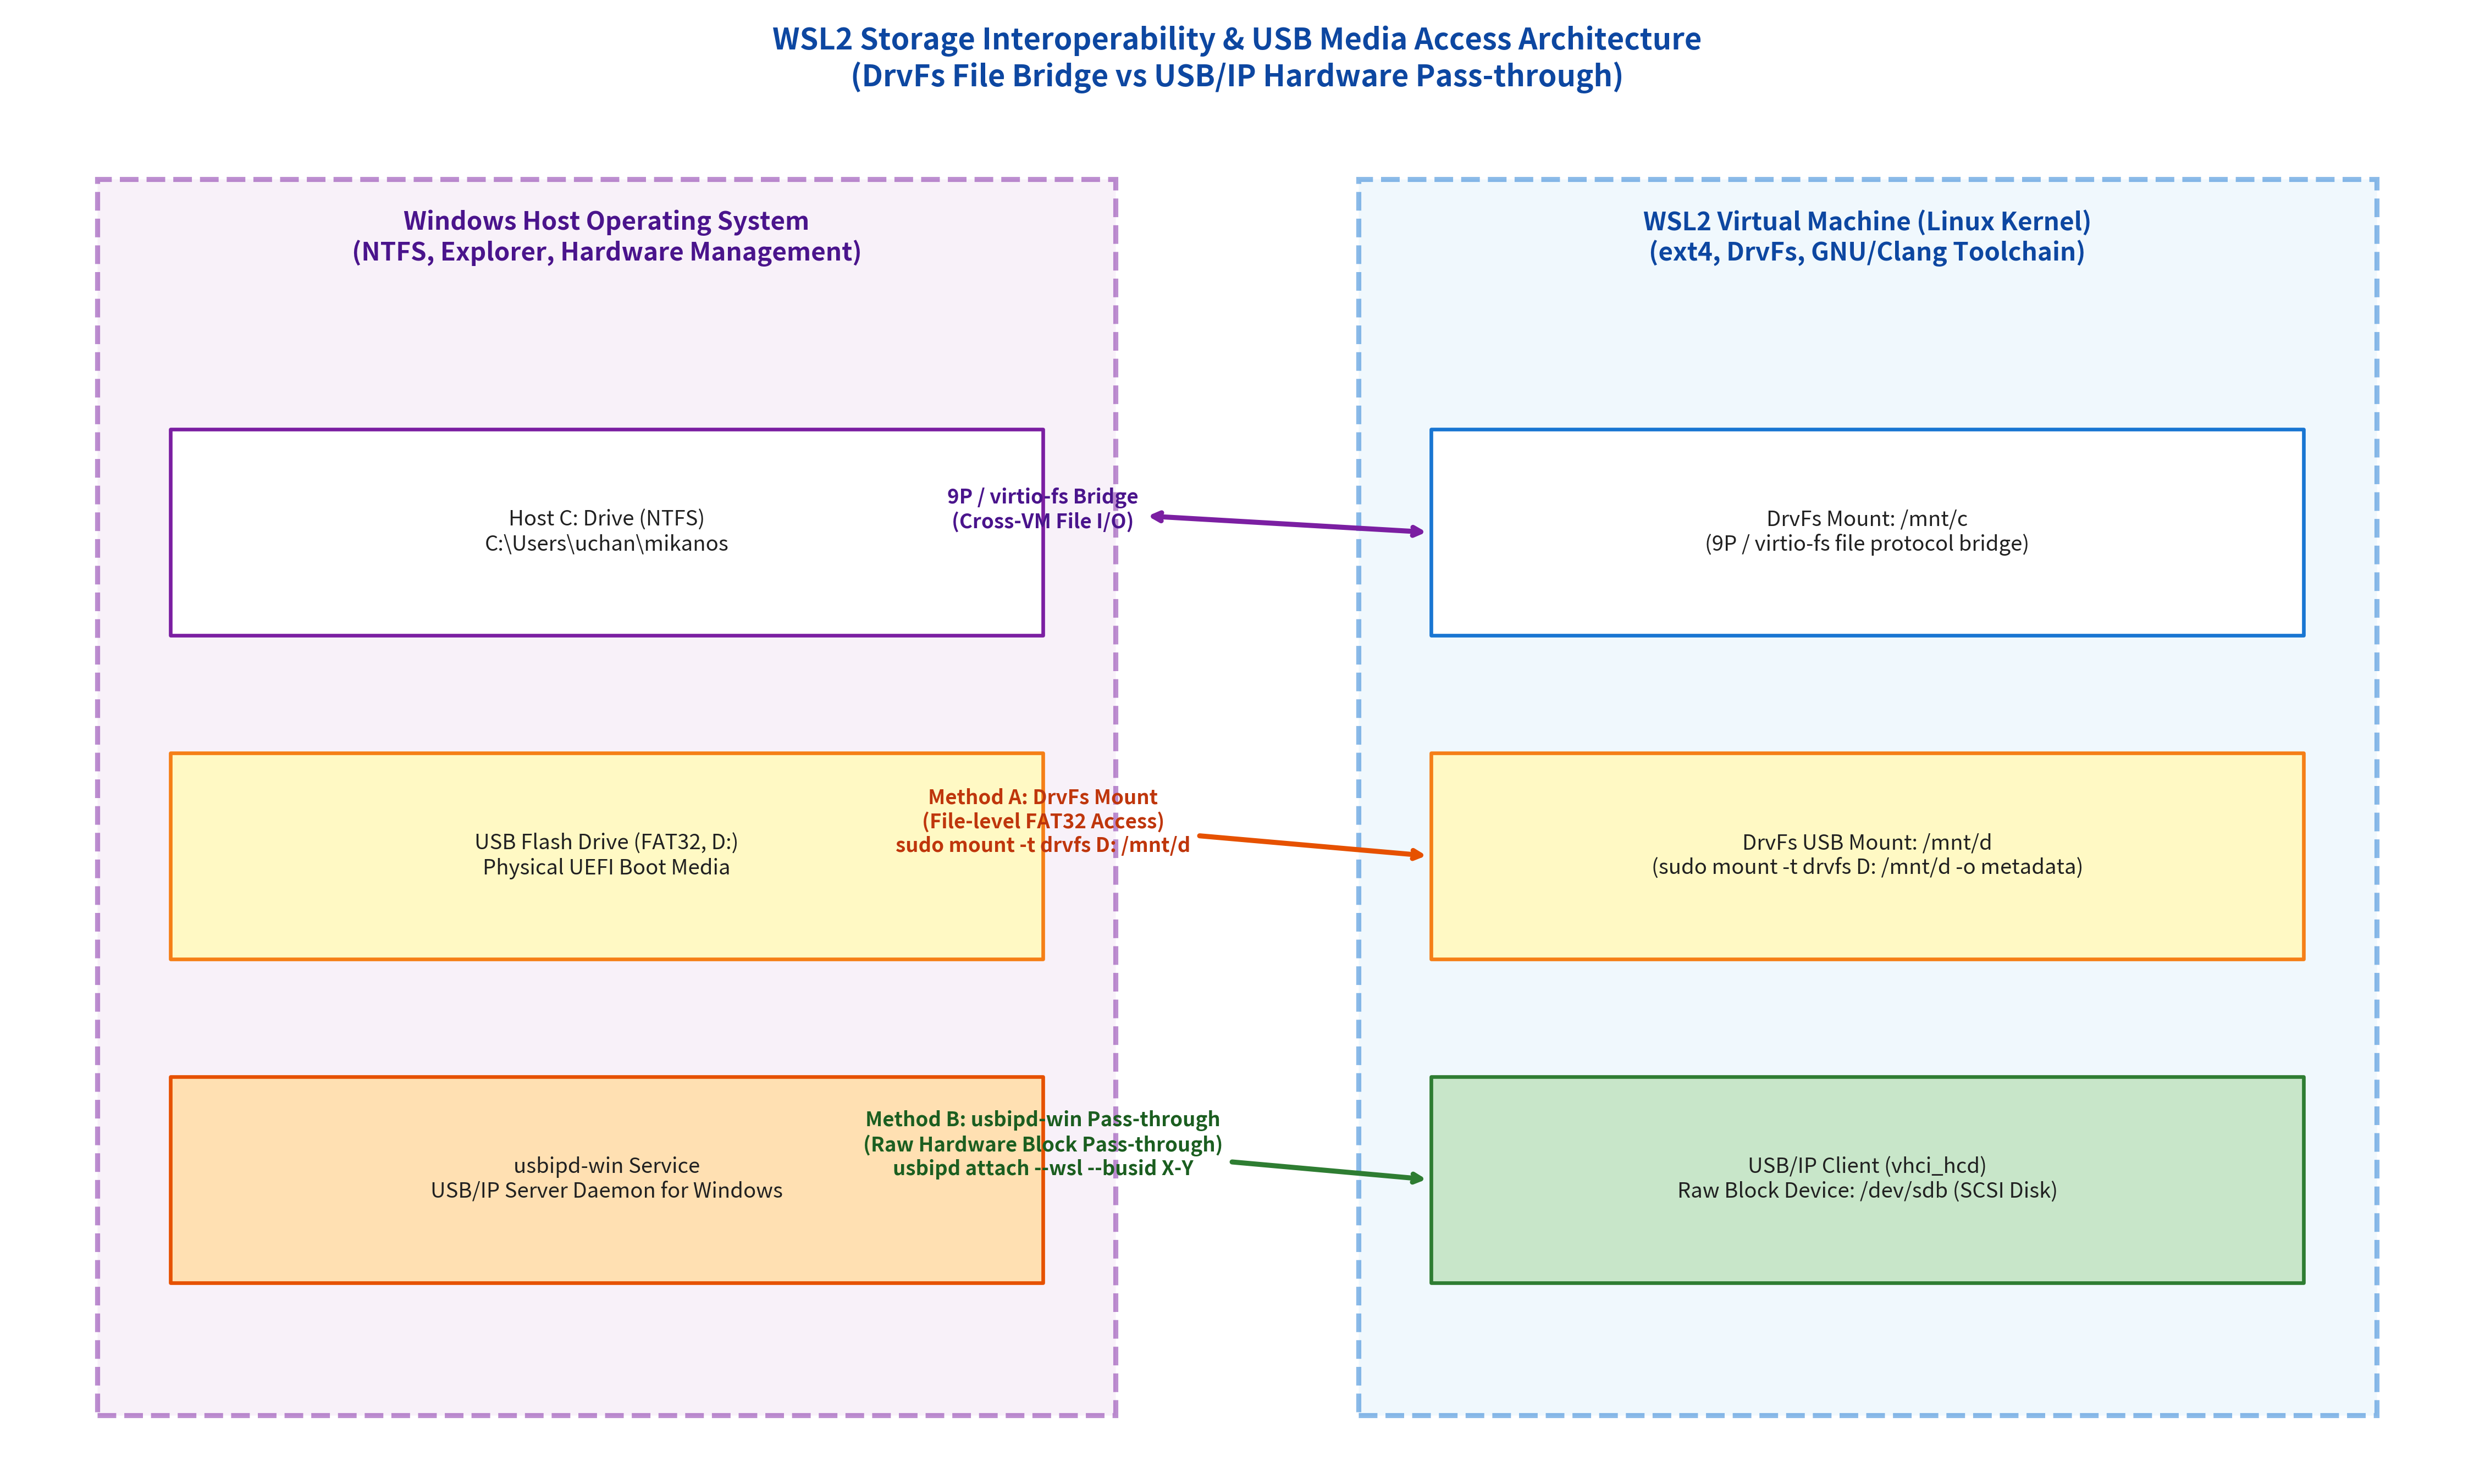

In [5]:
# === WSL2 ストレージ共有 & USB マウント構造図の生成と表示 ===
from IPython.display import Image, display
from common.os_sim import plot_wsl_storage_and_usb_mount

fig_path_storage = "result/fig1_6_wsl_storage_and_usb_mount.png"
plot_wsl_storage_and_usb_mount(fig_path_storage)
display(Image(filename=fig_path_storage, width=850))


## 5. 実践: WSL2 上での UEFI ブートメディア構築スクリプト

それでは、ビルドした UEFI アプリケーション（`hello.efi`）を、マウントした USB メモリへ安全に配置するワークフローを Python で自動化・検証します。

### 安全なデプロイメントの要件：
1. **マウント確認**: 既にマウントされているか検査し、未マウントの場合のみ安全に `mount -t drvfs` を実行する。
2. **ディレクトリ階層保証**: UEFI ファームウェアが最初に自動探索するパス `/EFI/BOOT`（大文字）を作成する。
3. **正確なリネーム**: 実行可能ファイル名を必ず **`BOOTX64.EFI`**（x86-64 UEFI 仕様におけるデフォルトブートローダ名）とする。
4. **`sync` の発行**: Linux のディスクライトバッファ（ダーティページ）を強制フラッシュし、USB メモリを抜いた際のバイナリ破損を防ぐ。


In [6]:
# === Python による安全な USB ブートメディア配置スクリプト生成と検証 ===
from common.os_sim import WSLStorageSimulator

# D: ドライブを対象としたデプロイメントスクリプトの自動生成
efi_source = "build/hello.efi"
target_drive = "D:"

script_lines = WSLStorageSimulator.generate_boot_media_copy_script(efi_source, target_drive)

print(f"=== 生成された WSL2 デプロイメント Bash スクリプト ({target_drive} ドライブ対象) ===")
for line in script_lines:
    print(line)


=== 生成された WSL2 デプロイメント Bash スクリプト (D: ドライブ対象) ===
# Check if Windows drive D: is mounted at /mnt/d
if ! mountpoint -q /mnt/d; then
    sudo mkdir -p /mnt/d
    sudo mount -t drvfs D: /mnt/d -o metadata,case=dir
fi
# Ensure target UEFI directory hierarchy exists (case-preserving)
sudo mkdir -p /mnt/d/EFI/BOOT
# Copy built EFI application to the standard UEFI fallback boot path
sudo cp build/hello.efi /mnt/d/EFI/BOOT/BOOTX64.EFI
# Flush OS buffers to ensure complete physical disk persistence
sync
echo 'Successfully deployed build/hello.efi -> /mnt/d/EFI/BOOT/BOOTX64.EFI'


## 6. C++20 による WSL 環境 & マウント自動検査ツールの実装

OS 開発環境のセットアップが正しく行われているかを自己診断するため、C++20 で実装された環境診断ツール `src/ch01/wsl_environment_inspector.cpp` をコンパイル・実行します。

### このツールの検査内容：
1. **ホスト環境自動判定**: `/proc/version` を解析し、WSL1 / WSL2 / Native Linux を正確に識別する。
2. **マウントテーブル走査**: `/proc/mounts` を走査し、活性化している DrvFs / 9P / virtio-fs マウントポイントを抽出する。
3. **パス変換エンジンの検証**: Windows パスと POSIX パス、UNC パスの相互変換を検証する。
4. **パーミッション計算エンジンの検証**: DrvFs の拡張メタデータ属性に応じた実効ファイル権限をビット計算する。


In [7]:
# === C++20 WSL 環境診断ツールのコンパイルと実行 ===
import subprocess

# 1. コンパイル実行 (C++20 -O2)
compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra",
    "../src/ch01/wsl_environment_inspector.cpp",
    "-o", "wsl_environment_inspector"
]
print("C++20 ソースコードをコンパイル中...")
res = subprocess.run(compile_cmd, capture_output=True, text=True)
if res.returncode != 0:
    print("❌ コンパイルエラー:")
    print(res.stderr)
else:
    print("✅ コンパイル成功: ./wsl_environment_inspector が生成されました。\n")

    # 2. 検証モード (--demo) での実行
    print("--- [検証モード (--demo) の実行結果] ---")
    demo_res = subprocess.run(["./wsl_environment_inspector", "--demo"], capture_output=True, text=True)
    print(demo_res.stdout)

    # 3. 実ホスト環境の診断実行
    print("--- [実ホスト環境のライブ診断結果] ---")
    live_res = subprocess.run(["./wsl_environment_inspector"], capture_output=True, text=True)
    print(live_res.stdout)


C++20 ソースコードをコンパイル中...


✅ コンパイル成功: ./wsl_environment_inspector が生成されました。

--- [検証モード (--demo) の実行結果] ---
  MikanOS WSL & Cross-Filesystem Inspector (Chapter 1.3)

[Mode] Running in Deterministic Verification Mode (--demo)

[1] Environment Detection Test:
  - Input 1: Linux version 5.15.153.1-microsoft-standard-WSL2 (x86_64)
    -> Detected: WSL2 (Hyper-V Utility VM + Native Linux Kernel)
  - Input 2: Linux version 4.4.0-19041-Microsoft (x86_64)
    -> Detected: WSL1 (System Call Emulation / LXCore.sys)
  - Input 3: Linux version 6.8.0-45-generic (buildd@lcy02-amd64-077) (x86_64)
    -> Detected: Native Linux (Direct Hardware / Bare Metal)

[2] Mount Table Parsing & DrvFs Identification:
  - Mount: /          Device: /dev/sdb     FS: ext4       DrvFs: NO
  - Mount: /init      Device: tools        FS: 9p         DrvFs: NO
  - Mount: /mnt/c     Device: C:\          FS: 9p         DrvFs: YES
  - Mount: /mnt/d     Device: D:\          FS: 9p         DrvFs: YES

[3] Bi-directional Path Translation Test:
  Windows P

## 7. コラム：OS 開発者が知っておくべき WSL の落とし穴とテクニック

---

### 💡 コラム 1.2: 改行コード CRLF の罠と `\r` 混入エラー
Windows 上のエディタ（メモ帳や一部の VS Code 設定）でシェルスクリプトや Makefile を保存すると、改行コードが **`CRLF` (`\r\n`)** になってしまうことがあります。

Linux のシェル（bash）は `\n` のみを改行と認識するため、`\r` をコマンド名や引数の一部として扱ってしまいます：
```bash
$ ./build.sh
bash: ./build.sh: /bin/bash^M: bad interpreter: No such file or directory
```
- **原因**: 1行目の `#!/bin/bash\r` の `\r` がインタープリタパスに含まれ、存在しない `/bin/bash\r` を探そうとするため。
- **対処法**:
  - VS Code の右下ステータスバーで改行コードを **`LF`** に明示的に設定する。
  - Git の自動変換を制御する: `.gitattributes` に `* text=auto eol=lf` を指定する。
  - 混入した場合は `dos2unix build.sh` または `sed -i 's/\r$//' build.sh` で一括除去する。

---

### 💡 コラム 1.3: `/etc/wsl.conf` でマウント設定を自動最適化する
WSL2 内の `/etc/wsl.conf` に以下の設定を記述しておくと、WSL2 起動時にすべての Windows ドライブが最適なパーミッション（`metadata`, `case=dir`）で自動マウントされます：

```ini
[automount]
enabled = true
options = "metadata,case=dir,umask=022,fmask=111,dmask=000"
mountFsTab = true

[network]
generateResolvConf = true

[interop]
enabled = true
appendWindowsPath = true
```

設定を反映するには、Windows PowerShell 側で `wsl --shutdown` を実行して WSL2 を再起動します。

---

### 💡 コラム 1.4: WSLg による GUI アプリケーション（QEMU 画面）の直接描画
Windows 11（および最新の Windows 10）では、**WSLg (*Windows Subsystem for Linux GUI*)** が標準で組み込まれています。

WSL2 内で QEMU などのグラフィカルなエミュレータを起動すると、Wayland プロトコル（または X11 プロトコル）を介して、Windows デスクトップ上に直接 QEMU のウィンドウが表示されます。
サードパーティの X サーバ（VcXsrv など）を別途インストール・起動する必要は一切ありません。


## 8. 本節のまとめと次節（1.4節 QEMUエミュレータ）への展望

### 📝 本節の総括
1. **WSL2 は純正 Linux カーネルを動かす軽量 Hyper-V 仮想マシン**であり、100% のシステムコール互換性と Docker/EDK II への完全対応を提供する。
2. **ソースコードやビルド成果物は必ず Linux ネイティブ領域（`/home/...`）に置く**。`/mnt/c` や `/mnt/d` などの DrvFs 領域は 9P/virtio-fs 通信が発生するため、ビルド用途には適さない。
3. **USB メモリへのアクセスには 2 つの手法**がある：
   - ドライブ単位の DrvFs マウント（`sudo mount -t drvfs D: /mnt/d`）：ファイル単位アクセス、手軽。
   - `usbipd-win` によるパススルー：RAW ブロックデバイスとして認識、低レイヤ制御可能。
4. **UEFI ブートローダの配置規則**: `/EFI/BOOT/BOOTX64.EFI` へコピー後、必ず `sync` を発行してディスクバッファをフラッシュする。

---

### 🚀 次節への展望：第1章 1.4 エミュレータでのやり方 (`1/1.4_Running_on_QEMU_OVMF.ipynb`)
実機の USB メモリへの書き込みと実機 PC の再起動による動作確認は、OS 自作の醍醐味である一方、デバッグサイクルが数分〜数十分単位と非常に遅くなってしまいます。

次節 **1.4節「エミュレータでのやり方」** では、PC を再起動することなく、**QEMU** と UEFI ファームウェア **OVMF (*Open Virtual Machine Firmware*)** を組み合わせ、数秒で UEFI アプリケーションを起動・テストできる高速検証環境の構築と内部動作を学びます！
